## Logistic Regression (Multiclass Classification)

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits 

In [3]:
digits = load_digits()

In [7]:
dir(digits)

['DESCR', 'data', 'feature_names', 'frame', 'images', 'target', 'target_names']

In [11]:
# the this dataset contains data of 1797 digit samples and each is a 8x8 array means each sample has 64 values

print(len(digits.data))
print(len(digits.data[0]))
print(digits.data[0])

1797
64
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


<Figure size 640x480 with 0 Axes>

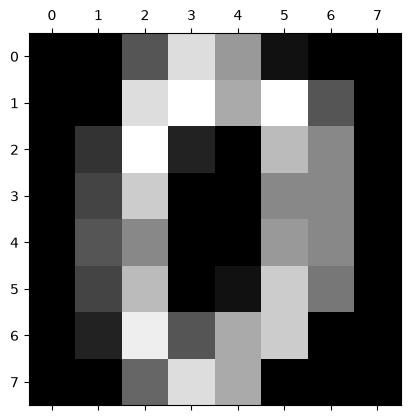

In [17]:
plt.gray()
plt.matshow(digits.images[0])

In [19]:
print(digits.target[0:20])

[0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]


In [18]:
from sklearn.model_selection import train_test_split

In [28]:
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.2)

In [29]:
print(len(x_train))
print(len(x_test))

1437
360


In [30]:
from sklearn.linear_model import LogisticRegression

In [32]:
model = LogisticRegression().fit(x_train, y_train)

d:\coding\MACHINE LEARNING\Codebasics Machine Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [33]:
model.score(x_test, y_test)

0.9527777777777777

6


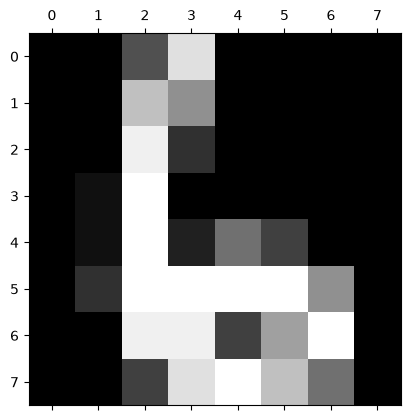

In [37]:
plt.matshow(digits.images[67])
print(digits.target[67])

In [41]:
model.predict([digits.data[67]])

array([6])

In [43]:
y_pred = model.predict(x_test)

In [44]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       0.95      0.95      0.95        40
           2       0.97      1.00      0.99        39
           3       0.94      0.97      0.95        32
           4       0.97      0.97      0.97        40
           5       0.94      0.96      0.95        46
           6       1.00      0.97      0.99        35
           7       0.89      0.92      0.91        26
           8       0.87      0.90      0.89        30
           9       0.98      0.89      0.93        46

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[26  0  0  0  0  0  0  0  0  0]
 [ 0 38  1  1  0  0  0  0  0  0]
 [ 0  0 39  0  0  0  0  0  0  0]
 [ 0  0  0 31  0  0  0  1  0  0]
 [ 0  1  0  0 39  0  0  0  0  0]
 [ 0  0  0  0  0 44  0  1  0  1]
 [ 0  0  0  0  0  1 34  0  0  0]
 [ 0  0  0  0  1  0  0 24  1  0]
 [ 0  1  0  0  0  1  0  1 27  0]
 [ 0  0  0  1  0  1  0  0  3 41]]


Text(45.83333333333333, 0.5, 'Truth')

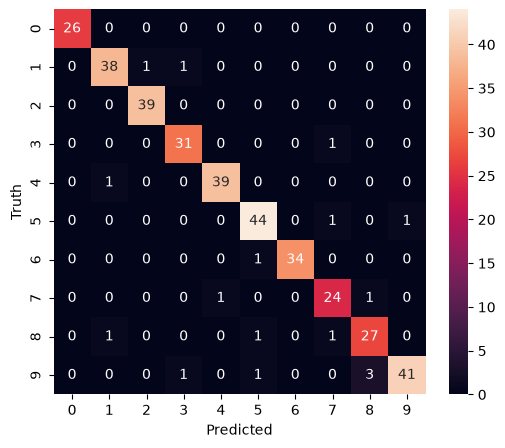

In [55]:
import seaborn as sn
plt.figure(figsize=(6, 5))
sn.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Truth")